# Stroke Prediction: Explainable AI with Tree SHAP and Kernel SHAP

**Assignment notebook — organised from the original working notebook.** The lecturer-provided implementation is retained as a reproduction exercise; the primary analysis uses training-only preprocessing, a Random Forest and an RBF Support Vector Machine (SVM).

**Important:** Saved outputs were generated in the original working session. Re-run all cells in order in your own VS Code environment to verify reproducibility. The underlying dataset and original lecturer scripts are not embedded in this notebook.

## 0. Setup and reproducibility

Use the same Python environment as the original experiment (Python 3.14.8). Required packages: pandas, NumPy, scikit-learn, imbalanced-learn, SHAP, matplotlib, seaborn. The original scripts additionally require the project files `utils.py`, `00_data_exploration.py`, `03_shap.py`, and `data/healthcare-dataset-stroke-data.csv`.

In [1]:

import sys
import importlib.metadata as metadata

print("EXPERIMENT REPRODUCIBILITY")
print("-" * 45)

print("Python:", sys.version.split()[0])

packages = [
    "pandas",
    "numpy",
    "scikit-learn",
    "shap",
    "matplotlib",
    "seaborn",
    "imbalanced-learn"
]

for package in packages:
    print(f"{package}: {metadata.version(package)}")

print("\nEXPERIMENT SETTINGS")
print("-" * 45)

print("Train/test split: 80/20")
print("Split seed: 2021")
print("Stratified split: Yes")
print("Oversampling seed: 42")
print("Random Forest seed: 42")
print("SVM seed: 42")
print("Kernel SHAP background: 50 observations")
print("Kernel SHAP explained: 10 observations")
print("Kernel SHAP nsamples: 100")


EXPERIMENT REPRODUCIBILITY
---------------------------------------------
Python: 3.14.8
pandas: 3.0.6
numpy: 2.5.4
scikit-learn: 1.9.1
shap: 0.54.1
matplotlib: 3.11.2
seaborn: 0.13.2
imbalanced-learn: 0.14.2

EXPERIMENT SETTINGS
---------------------------------------------
Train/test split: 80/20
Split seed: 2021
Stratified split: Yes
Oversampling seed: 42
Random Forest seed: 42
SVM seed: 42
Kernel SHAP background: 50 observations
Kernel SHAP explained: 10 observations
Kernel SHAP nsamples: 100


## 1. Task 1 — Exploratory Data Analysis

Run the lecturer-provided EDA script. The stroke dataset contains 5,110 records, with 249 recorded stroke cases and 201 missing BMI entries. The target is a **recorded stroke label**, not a validated prediction of future stroke risk. Examine class imbalance, missingness and feature distributions.

(5110, 12)
<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 479.2 KB
col:  id


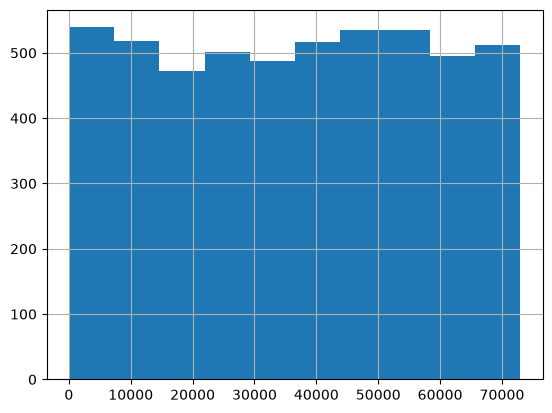

col:  gender


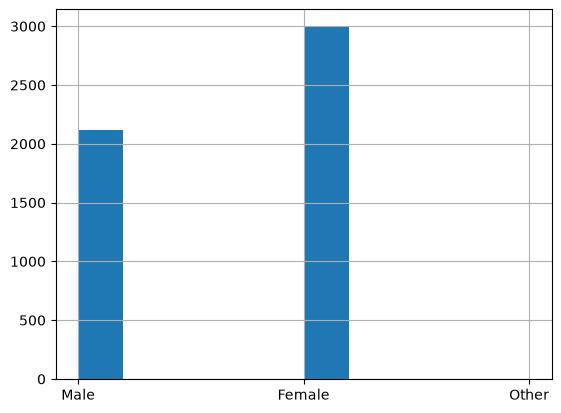

col:  age


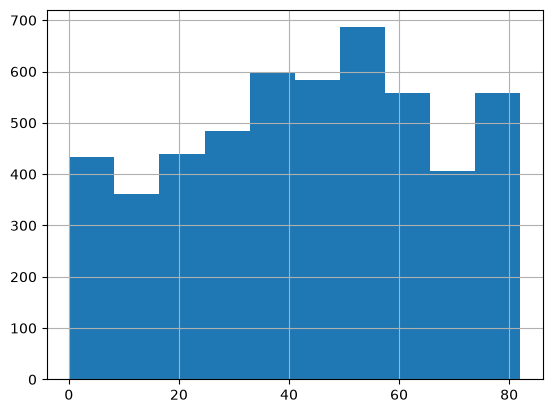

col:  hypertension


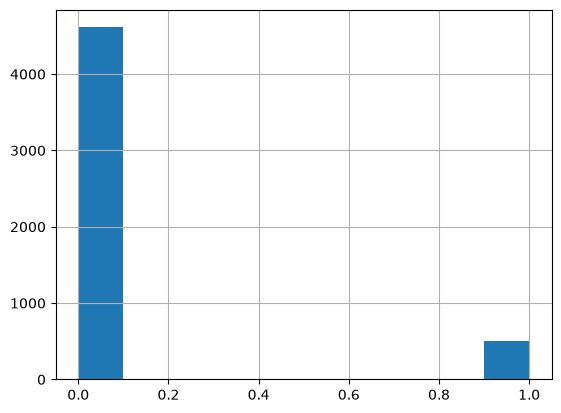

col:  heart_disease


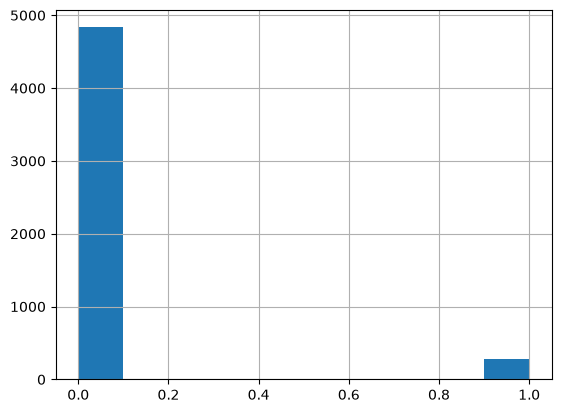

col:  ever_married


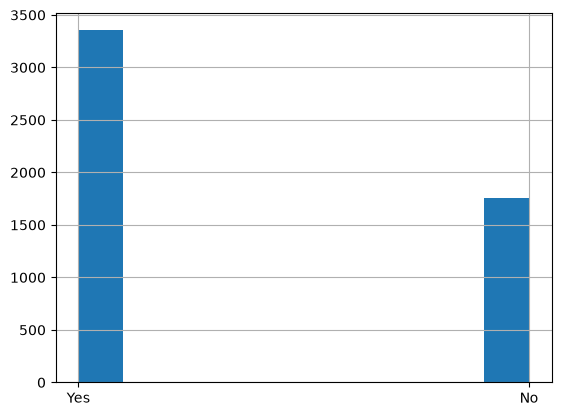

col:  work_type


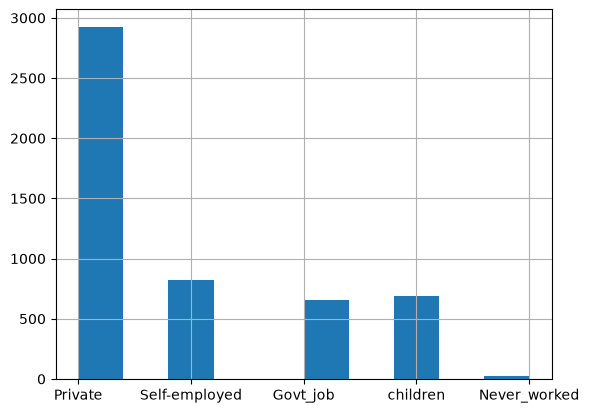

col:  Residence_type


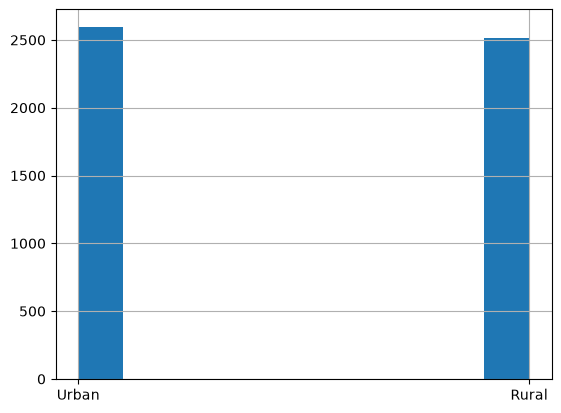

col:  avg_glucose_level


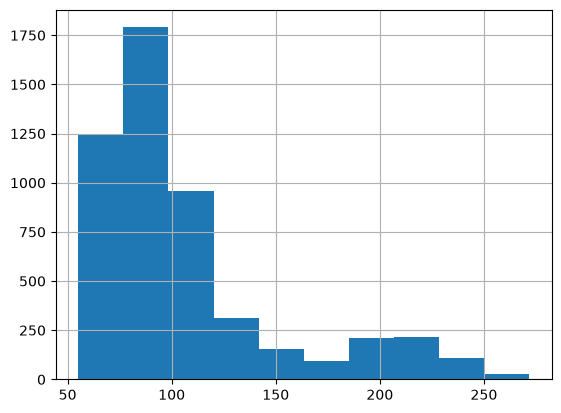

col:  bmi


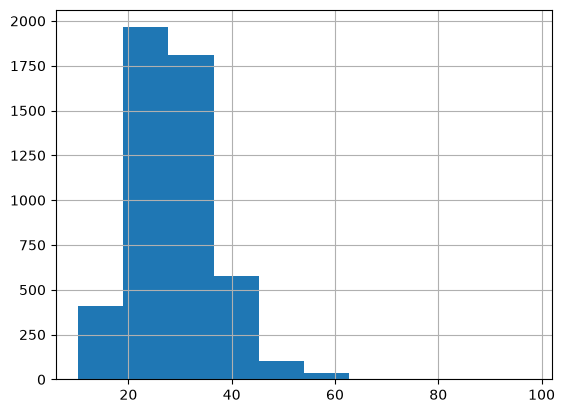

col:  smoking_status


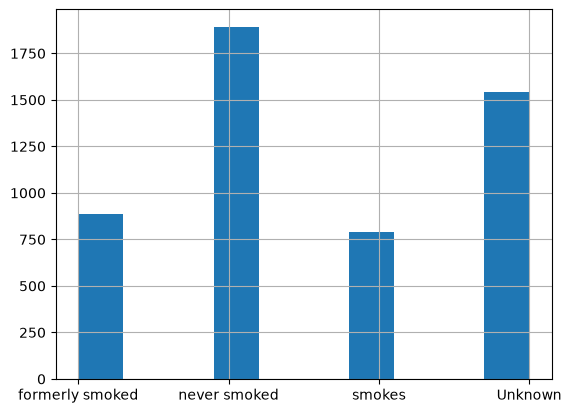

col:  stroke


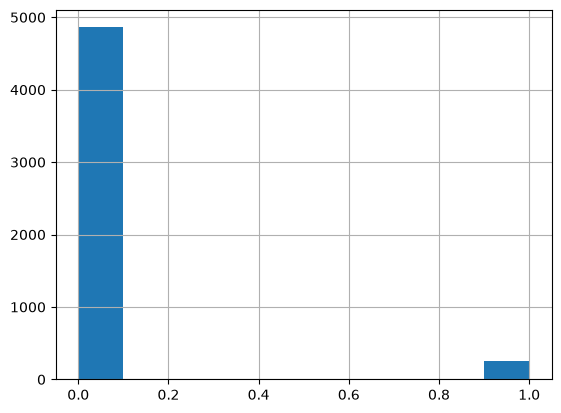

In [2]:
%run 00_data_exploration.py

In [3]:
import pandas as pd

df = pd.read_csv("data/healthcare-dataset-stroke-data.csv")

print("Dataset shape:", df.shape)

Dataset shape: (5110, 12)


In [4]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate IDs:", df["id"].duplicated().sum())

Duplicate rows: 0
Duplicate IDs: 0


In [5]:
unknown_count = (df["smoking_status"] == "Unknown").sum()
unknown_pct = unknown_count / len(df) * 100

print(f"Unknown smoking status: {unknown_count} ({unknown_pct:.2f}%)")

Unknown smoking status: 1544 (30.22%)


In [6]:
columns = ["age", "avg_glucose_level", "bmi"]

print(
    df[columns]
    .describe()
    .round(2)
)

           age  avg_glucose_level      bmi
count  5110.00            5110.00  4909.00
mean     43.23             106.15    28.89
std      22.61              45.28     7.85
min       0.08              55.12    10.30
25%      25.00              77.24    23.50
50%      45.00              91.88    28.10
75%      61.00             114.09    33.10
max      82.00             271.74    97.60


In [7]:
for col in columns:
    median = df[col].median()
    iqr = df[col].quantile(0.75) - df[col].quantile(0.25)

    print(f"{col}: Median = {median:.2f}, IQR = {iqr:.2f}")

age: Median = 45.00, IQR = 36.00
avg_glucose_level: Median = 91.88, IQR = 36.84
bmi: Median = 28.10, IQR = 9.60


In [8]:
categorical_columns = [
    "gender",
    "hypertension",
    "heart_disease",
    "ever_married",
    "work_type",
    "Residence_type",
    "smoking_status"
]

for col in categorical_columns:
    print(f"\n--- {col} ---")

    counts = df[col].value_counts(dropna=False)
    percentages = df[col].value_counts(
        normalize=True, dropna=False
    ) * 100

    result = pd.DataFrame({
        "Count": counts,
        "Percentage (%)": percentages.round(2)
    })

    print(result)


--- gender ---
        Count  Percentage (%)
gender                       
Female   2994           58.59
Male     2115           41.39
Other       1            0.02

--- hypertension ---
              Count  Percentage (%)
hypertension                       
0              4612           90.25
1               498            9.75

--- heart_disease ---
               Count  Percentage (%)
heart_disease                       
0               4834            94.6
1                276             5.4

--- ever_married ---
              Count  Percentage (%)
ever_married                       
Yes            3353           65.62
No             1757           34.38

--- work_type ---
               Count  Percentage (%)
work_type                           
Private         2925           57.24
Self-employed    819           16.03
children         687           13.44
Govt_job         657           12.86
Never_worked      22            0.43

--- Residence_type ---
                Count  Percen

## 2. Reproduce the lecturer's original Tree SHAP demonstration (baseline)

This optional reproduction uses the lecturer's `utils.py` and `03_shap.py` with the original preprocessing. It is **not** the primary model comparison. The original code replaces missing BMI with zero and uses a non-stratified split; see the methodological discussion below. The saved output is from a previous execution.

c:\Users\PavinthranALGanesh\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Training shape: (7778, 21)
Testing shape: (1022, 21)
F1 Score (Macro): 0.5293
Accuracy: 0.9403

Classification Report:
              precision    recall  f1-score   support

   No Stroke       0.95      0.99      0.97       972
      Stroke       0.18      0.06      0.09        50

    accuracy                           0.94      1022
   macro avg       0.56      0.52      0.53      1022
weighted avg       0.92      0.94      0.93      1022



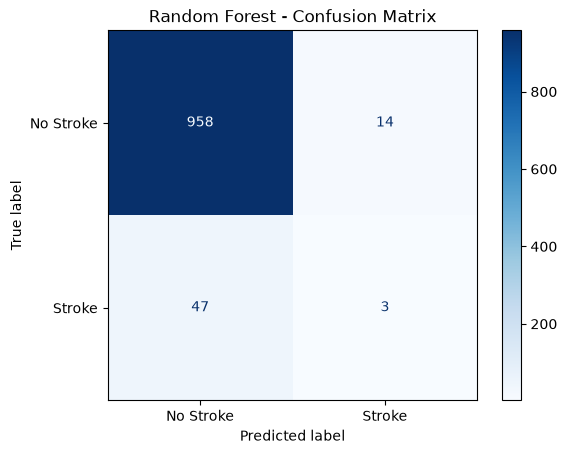

SHAP values shape: (1, 21)
The RF predicted: 0
Predicted stroke probability: 0.00%


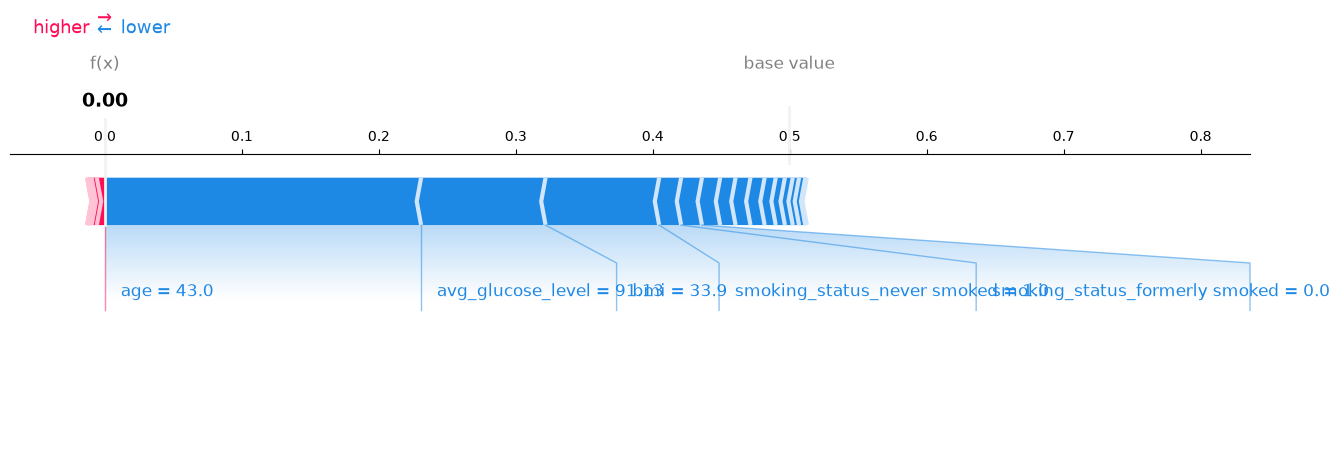

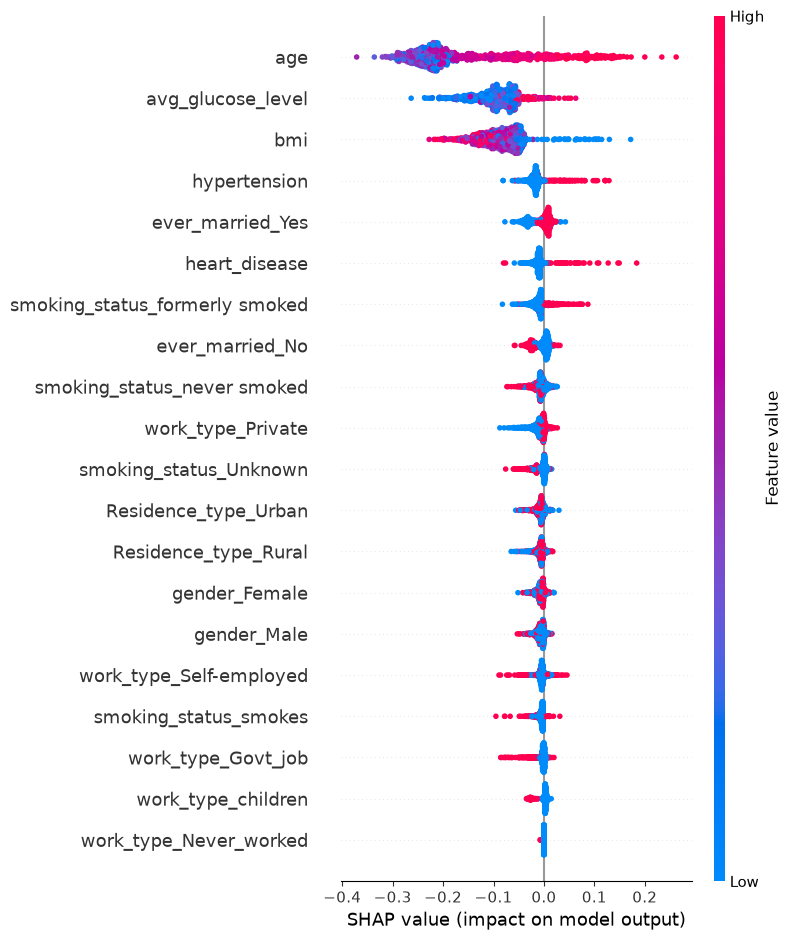

In [12]:
%run 03_shap.py

## Task 2 — Improved data preparation (primary experiments)

Changes from the baseline: split before fitted transformations, stratify on the stroke label, fit median BMI imputation on training data only, align encoded test features to the training feature vocabulary, and oversample only the training data with a fixed seed. These changes improve methodological safeguards; they do **not** guarantee better classification accuracy. The original baseline and improved pipeline should not be described as a controlled single-variable comparison.

In [13]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from imblearn.over_sampling import RandomOverSampler

class ImprovedDataLoader:
    def __init__(self):
        self.data = None
        self.imputer = SimpleImputer(strategy="median")

    def load_dataset(self, path="data/healthcare-dataset-stroke-data.csv"):
        self.data = pd.read_csv(path)

    def get_data_split(self):
        X = self.data.drop(columns=["id", "stroke"])
        y = self.data["stroke"]
        return train_test_split(X, y, test_size=0.20,
                                random_state=2021, stratify=y)

    def preprocess_split(self, X_train, X_test):
        X_train, X_test = X_train.copy(), X_test.copy()
        X_train["bmi"] = self.imputer.fit_transform(X_train[["bmi"]]).ravel()
        X_test["bmi"] = self.imputer.transform(X_test[["bmi"]]).ravel()
        categorical_cols = ["gender", "ever_married", "work_type",
                            "Residence_type", "smoking_status"]
        X_train = pd.get_dummies(X_train, columns=categorical_cols, dtype=int)
        X_test = pd.get_dummies(X_test, columns=categorical_cols, dtype=int)
        X_test = X_test.reindex(columns=X_train.columns, fill_value=0)
        return X_train, X_test

    def oversample(self, X_train, y_train):
        sampler = RandomOverSampler(sampling_strategy="minority", random_state=42)
        return sampler.fit_resample(X_train, y_train)

In [14]:
loader = ImprovedDataLoader()
loader.load_dataset()

X_train, X_test, y_train, y_test = loader.get_data_split()

X_train, X_test = loader.preprocess_split(
    X_train, X_test
)

X_train_balanced, y_train_balanced = loader.oversample(
    X_train, y_train
)

print("Training:", X_train.shape)
print("Balanced training:", X_train_balanced.shape)
print("Testing:", X_test.shape)

print("\nTraining classes:")
print(y_train.value_counts())

print("\nBalanced classes:")
print(y_train_balanced.value_counts())

print("\nTesting classes:")
print(y_test.value_counts())

print("\nMissing values:")
print("Training:", X_train.isna().sum().sum())
print("Testing:", X_test.isna().sum().sum())

Training: (4088, 21)
Balanced training: (7778, 21)
Testing: (1022, 21)

Training classes:
stroke
0    3889
1     199
Name: count, dtype: int64

Balanced classes:
stroke
0    3889
1    3889
Name: count, dtype: int64

Testing classes:
stroke
0    972
1     50
Name: count, dtype: int64

Missing values:
Training: 0
Testing: 0


The original run produced 4,088 training records (199 stroke, 3,889 no stroke) and 1,022 untouched test records (50 stroke, 972 no stroke). Oversampling balanced the training set to 3,889 per class; the test set remained unbalanced. No missing values remained after preprocessing.

### Task 2 — Improved Random Forest and model evaluation

Evaluate the stroke class (label 1), with particular attention to recall, precision, average precision and balanced accuracy. High overall accuracy can be misleading with an imbalanced target.

In [15]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

# Train the improved Random Forest
rf_improved = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_improved.fit(X_train_balanced, y_train_balanced)

# Predict using the untouched test set
y_pred = rf_improved.predict(X_test)
y_prob = rf_improved.predict_proba(X_test)[:, 1]

# Evaluate model performance
print("IMPROVED RANDOM FOREST RESULTS")
print("-" * 40)

print("Accuracy:",
      round(accuracy_score(y_test, y_pred), 4))

print("Balanced Accuracy:",
      round(balanced_accuracy_score(y_test, y_pred), 4))

print("Stroke Precision:",
      round(precision_score(y_test, y_pred, zero_division=0), 4))

print("Stroke Recall:",
      round(recall_score(y_test, y_pred, zero_division=0), 4))

print("Stroke F1:",
      round(f1_score(y_test, y_pred, zero_division=0), 4))

print("ROC AUC:",
      round(roc_auc_score(y_test, y_prob), 4))

print("Average Precision:",
      round(average_precision_score(y_test, y_prob), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


IMPROVED RANDOM FOREST RESULTS
----------------------------------------
Accuracy: 0.9384
Balanced Accuracy: 0.5028
Stroke Precision: 0.0667
Stroke Recall: 0.02
Stroke F1: 0.0308
ROC AUC: 0.8149
Average Precision: 0.1324

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.99      0.97       972
           1       0.07      0.02      0.03        50

    accuracy                           0.94      1022
   macro avg       0.51      0.50      0.50      1022
weighted avg       0.91      0.94      0.92      1022


Confusion Matrix:
[[958  14]
 [ 49   1]]


**Observed result:** accuracy 0.9384, balanced accuracy 0.5028, stroke precision 0.0667, stroke recall 0.0200, ROC AUC 0.8149 and average precision 0.1324. The confusion matrix `[[958, 14], [49, 1]]` means that only 1 of 50 stroke-labelled test records was detected at the default decision threshold.

## Task 3 — Local Tree SHAP and additivity check

The example is selected from records with actual stroke label 1. Its predicted stroke probability is 0.23, below the 0.50 threshold, so it is a **false negative**. The ~0.50 SHAP baseline is a model reference value influenced by the oversampled training distribution, not population stroke prevalence.

In [16]:
# Compute Tree SHAP before using it in local or global explanations.
import shap
import numpy as np

explainer_rf = shap.TreeExplainer(rf_improved)
shap_values_rf = explainer_rf.shap_values(X_test)

# Select SHAP contributions for the stroke class (class 1).
if isinstance(shap_values_rf, list):
    shap_stroke = shap_values_rf[1]
elif np.asarray(shap_values_rf).ndim == 3:
    shap_stroke = shap_values_rf[:, :, 1]
else:
    shap_stroke = shap_values_rf

print("Tree SHAP ready:", shap_stroke.shape)


Tree SHAP ready: (1022, 21)


Patient index: 32
Actual class: 1
Predicted class: 0
Predicted stroke probability: 23.0 %

SHAP base value: 0.500171
Sum of SHAP values: -0.270171
Reconstructed prediction: 0.23
Model probability: 0.23
Reconstruction error: 4.163336342344337e-16


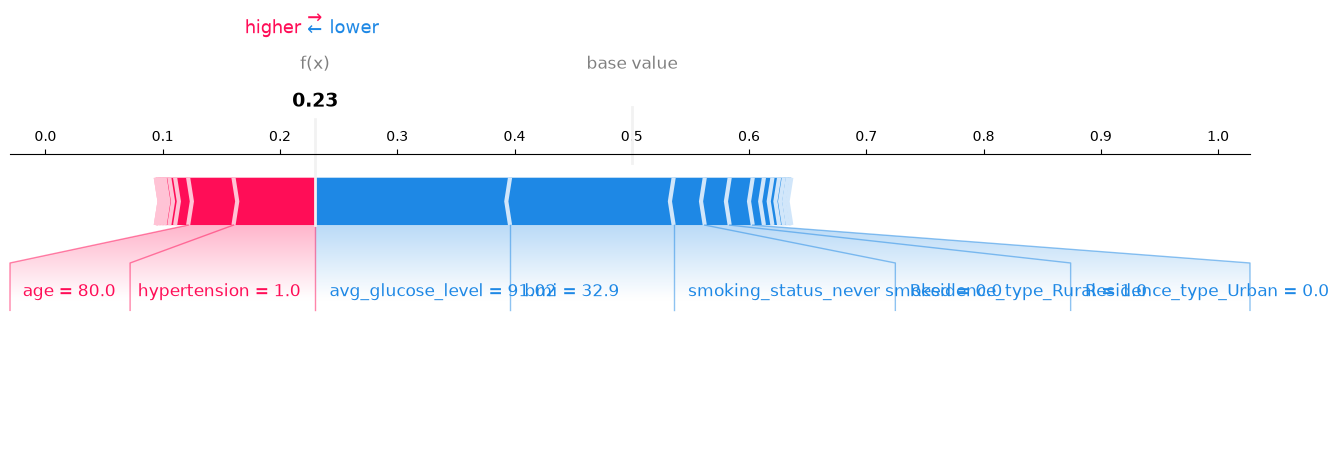

In [17]:

import shap
import numpy as np
import matplotlib.pyplot as plt

# Select the first actual stroke case in the test set
stroke_positions = np.where(
    y_test.to_numpy() == 1
)[0]

patient_index = int(stroke_positions[0])

# Get patient features
patient = X_test.iloc[[patient_index]]

# Model prediction
prediction = rf_improved.predict(patient)[0]
probability = rf_improved.predict_proba(patient)[0, 1]

print("Patient index:", patient_index)
print("Actual class:", y_test.iloc[patient_index])
print("Predicted class:", prediction)
print("Predicted stroke probability:",
      round(probability * 100, 2), "%")

# Get class 1 SHAP values
patient_shap = shap_stroke[patient_index]

# Get expected value for class 1
base_values = np.asarray(explainer_rf.expected_value)
base_value = float(base_values.reshape(-1)[1])

# Verify SHAP reconstruction
reconstructed = base_value + np.sum(patient_shap)

print("\nSHAP base value:", round(base_value, 6))
print("Sum of SHAP values:",
      round(np.sum(patient_shap), 6))
print("Reconstructed prediction:",
      round(reconstructed, 6))
print("Model probability:",
      round(probability, 6))
print("Reconstruction error:",
      abs(reconstructed - probability))

# Generate local force plot
shap.force_plot(
    base_value,
    patient_shap,
    patient.iloc[0],
    matplotlib=True,
    show=False,
    figsize=(16, 4)
)

plt.savefig(
    "improved_rf_shap_force.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [18]:
import numpy as np

patient = X_test.iloc[[patient_index]]

rf_probability = rf_improved.predict_proba(patient)[0, 1]
rf_reconstructed = float(base_value + np.sum(shap_stroke[patient_index]))

print("RF predicted probability:", rf_probability)
print("RF SHAP reconstructed probability:", rf_reconstructed)
print("RF reconstruction error:", abs(rf_probability - rf_reconstructed))

RF predicted probability: 0.23
RF SHAP reconstructed probability: 0.23000000000000043
RF reconstruction error: 4.163336342344337e-16


In [19]:
print("Test dataset shape:", X_test.shape)
print("Selected patient index:", patient_index)
print("SHAP values shape:", shap_stroke.shape)
print("Predicted probability:",
      rf_improved.predict_proba(
          X_test.iloc[[patient_index]]
      )[0, 1])

Test dataset shape: (1022, 21)
Selected patient index: 32
SHAP values shape: (1022, 21)
Predicted probability: 0.23


In [20]:
import pandas as pd
import numpy as np

contributions = pd.DataFrame({
    "Feature": X_test.columns,
    "Patient value": X_test.iloc[patient_index].values,
    "SHAP value": shap_stroke[patient_index]
})

contributions["Direction"] = np.where(
    contributions["SHAP value"] > 0,
    "Increases stroke output",
    "Decreases stroke output"
)

contributions = contributions.reindex(
    contributions["SHAP value"].abs().sort_values(
        ascending=False
    ).index
)

print(contributions.to_string(index=False))

                       Feature  Patient value    SHAP value               Direction
             avg_glucose_level          91.02 -1.661931e-01 Decreases stroke output
                           bmi          32.90 -1.395129e-01 Decreases stroke output
                  hypertension           1.00  6.961790e-02 Increases stroke output
                           age          80.00  3.868770e-02 Increases stroke output
   smoking_status_never smoked           0.00 -2.652015e-02 Decreases stroke output
          Residence_type_Rural           1.00 -2.125259e-02 Decreases stroke output
          Residence_type_Urban           0.00 -1.967835e-02 Decreases stroke output
       work_type_Self-employed           1.00  1.110149e-02 Increases stroke output
                 heart_disease           0.00 -9.525827e-03 Decreases stroke output
                 gender_Female           1.00 -7.263689e-03 Decreases stroke output
            work_type_Govt_job           0.00 -5.688696e-03 Decreases stroke

**Observed verification:** model probability 0.23; SHAP reconstruction 0.23000000000000043; absolute error approximately 4.16 × 10⁻¹⁶. The additivity check confirms numerical consistency, not predictive validity.

## Task 4 — Global Tree SHAP

Tree SHAP values below are for class 1 (stroke). The beeswarm displays feature-level contributions to the **model output**, not clinical causal effects.

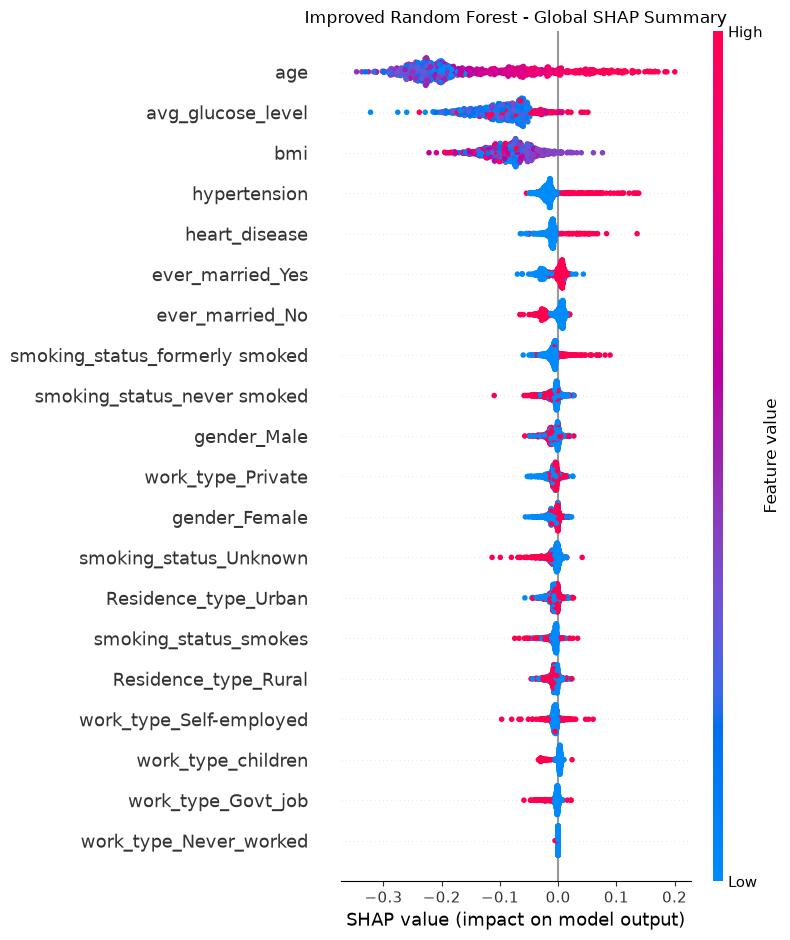

In [21]:

import shap
import matplotlib.pyplot as plt
import numpy as np

# Reuse stroke-class SHAP values computed before the local explanation.
# Generate global SHAP summary plot
shap.summary_plot(
    shap_stroke,
    X_test,
    show=False
)

plt.title("Improved Random Forest - Global SHAP Summary")
plt.tight_layout()
plt.savefig(
    "improved_rf_shap_summary.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [22]:

import pandas as pd
import numpy as np

# Calculate mean absolute SHAP importance
mean_abs_shap = np.abs(shap_stroke).mean(axis=0)

feature_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean Absolute SHAP": mean_abs_shap
})

feature_importance = feature_importance.sort_values(
    "Mean Absolute SHAP",
    ascending=False
)

print("TOP 5 GLOBAL SHAP FEATURES")
print("-" * 45)
print(feature_importance.head(5).to_string(index=False))

# Save complete ranking for the report
feature_importance.to_csv(
    "improved_rf_shap_feature_importance.csv",
    index=False
)


TOP 5 GLOBAL SHAP FEATURES
---------------------------------------------
          Feature  Mean Absolute SHAP
              age            0.161944
avg_glucose_level            0.092898
              bmi            0.081831
     hypertension            0.021243
    heart_disease            0.013063


**Observed global ranking (mean absolute SHAP, 1,022 test records):** age 0.161944; average glucose 0.092898; BMI 0.081831; hypertension 0.021243; heart disease 0.013063. Mean absolute SHAP quantifies contribution magnitude, not direction.

## Task 5 — Three audience-specific slides

Create **exactly three slides** as a separate presentation: (1) data scientist — evaluation metrics, class imbalance and global SHAP; (2) doctor — local explanation, false negatives and limitations; (3) patient — plain-language description without implying that the model output is a clinically validated risk estimate. The slides are a separate required deliverable.

### Patient-facing contribution diagram

This visual is a **static illustration using the previously observed Random Forest case contributions**, not a recomputation of SHAP. If the final rerun changes the selected case or contributions, update the hard-coded values in the next cell before exporting the slide. It is not clinical advice.

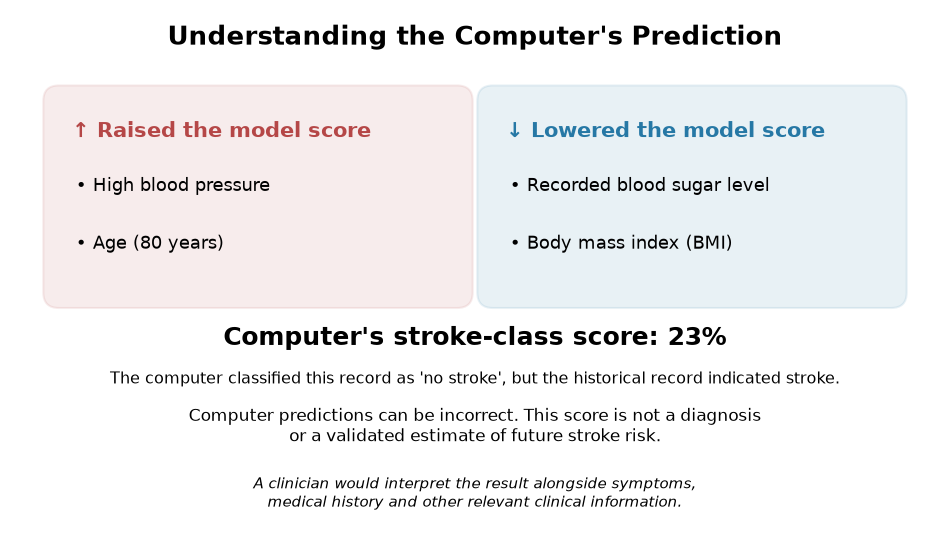

In [23]:

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

# Verified SHAP contributions for the selected observation
factors = [
    ("High blood pressure", 0.06961796),
    ("Age (80 years)", 0.03868770),
    ("Recorded blood sugar level", -0.1661931),
    ("Body mass index (BMI)", -0.1395129)
]

fig, ax = plt.subplots(figsize=(12, 7))
fig.patch.set_facecolor("white")
ax.set_xlim(0, 12)
ax.set_ylim(0, 7)
ax.axis("off")

ax.text(6, 6.55, "Understanding the Computer's Prediction",
        ha="center", fontsize=19, fontweight="bold")

def panel(x, title, entries, color):
    rect = FancyBboxPatch(
        (x, 3.25), 5.3, 2.65,
        boxstyle="round,pad=0.12,rounding_size=0.2",
        facecolor=color, alpha=0.10,
        edgecolor=color, linewidth=1.5
    )
    ax.add_patch(rect)
    ax.text(x + 0.25, 5.35, title,
            fontsize=15, fontweight="bold", color=color)
    for i, label in enumerate(entries):
        ax.text(x + 0.3, 4.65 - i * 0.75,
                "• " + label, fontsize=13)

panel(
    0.55, "↑ Raised the model score",
    [name for name, value in factors if value > 0],
    "#B54747"
)

panel(
    6.15, "↓ Lowered the model score",
    [name for name, value in factors if value < 0],
    "#2678A5"
)

ax.text(6, 2.65, "Computer's stroke-class score: 23%",
        ha="center", fontsize=18, fontweight="bold")

ax.text(6, 2.15,
        "The computer classified this record as 'no stroke', "
        "but the historical record indicated stroke.",
        ha="center", fontsize=11.5)

ax.text(6, 1.40,
        "Computer predictions can be incorrect. This score is not a diagnosis\n"
        "or a validated estimate of future stroke risk.",
        ha="center", fontsize=12)

ax.text(6, 0.55,
        "A clinician would interpret the result alongside symptoms,\n"
        "medical history and other relevant clinical information.",
        ha="center", fontsize=11, fontstyle="italic")

plt.savefig(
    "patient_friendly_shap_explanation.png",
    dpi=300, bbox_inches="tight", facecolor="white"
)
plt.show()


## Task 6 — Different black-box model: RBF SVM

The SVM uses the same improved training/test records as the improved Random Forest. Scaling is fitted through the pipeline on training data only. Kernel SHAP explains the SVM's predicted class-1 probability.

In [24]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

# Scaling is fitted on the training data only.
# The pipeline applies the same transformation to test data.
svm_model = make_pipeline(
    StandardScaler(),
    SVC(
        kernel="rbf",
        probability=True,
        random_state=42
    )
)

svm_model.fit(X_train_balanced, y_train_balanced)

svm_pred = svm_model.predict(X_test)
svm_prob = svm_model.predict_proba(X_test)[:, 1]

print("SVM RESULTS")
print("-" * 40)

print("Accuracy:",
      round(accuracy_score(y_test, svm_pred), 4))
print("Balanced Accuracy:",
      round(balanced_accuracy_score(y_test, svm_pred), 4))
print("Stroke Precision:",
      round(precision_score(y_test, svm_pred, zero_division=0), 4))
print("Stroke Recall:",
      round(recall_score(y_test, svm_pred, zero_division=0), 4))
print("Stroke F1:",
      round(f1_score(y_test, svm_pred, zero_division=0), 4))
print("ROC AUC:",
      round(roc_auc_score(y_test, svm_prob), 4))
print("Average Precision:",
      round(average_precision_score(y_test, svm_prob), 4))

print("\nClassification Report:")
print(classification_report(
    y_test, svm_pred, zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, svm_pred))


c:\Users\PavinthranALGanesh\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM RESULTS
----------------------------------------
Accuracy: 0.7622
Balanced Accuracy: 0.6948
Stroke Precision: 0.1216
Stroke Recall: 0.62
Stroke F1: 0.2033
ROC AUC: 0.7893
Average Precision: 0.1556

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.77      0.86       972
           1       0.12      0.62      0.20        50

    accuracy                           0.76      1022
   macro avg       0.55      0.69      0.53      1022
weighted avg       0.93      0.76      0.83      1022


Confusion Matrix:
[[748 224]
 [ 19  31]]


**Observed SVM performance:** accuracy 0.7622; balanced accuracy 0.6948; stroke precision 0.1216; recall 0.62; F1 0.2033; ROC AUC 0.7893; average precision 0.1556. Confusion matrix `[[748, 224], [19, 31]]`. SVM detected 31/50 stroke-labelled records but produced 224 false positives.

### Task 6.1 — Kernel SHAP background and local explanation

The original local example uses a 50-row sample of the **unoversampled training set** as background and 10 test observations, with `nsamples=100`. The SVM local example is a correctly classified no-stroke observation, not the same patient as the Random Forest example.

In [25]:

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

# Use a reproducible sample from the original training set
# rather than the oversampled training set
background = X_train.sample(
    n=50,
    random_state=42
)

# Select 10 test observations
X_explain = X_test.sample(
    n=10,
    random_state=42
)

# Define function returning stroke-class probability
def predict_stroke_probability(data):
    data_df = pd.DataFrame(
        data,
        columns=X_train.columns
    )
    return svm_model.predict_proba(data_df)[:, 1]

# Create Kernel SHAP explainer
start_time = time.time()

kernel_explainer = shap.KernelExplainer(
    predict_stroke_probability,
    background
)

# Calculate SHAP values
kernel_shap_values = kernel_explainer.shap_values(
    X_explain,
    nsamples=100
)

elapsed_time = time.time() - start_time

print("Kernel SHAP completed!")
print("SHAP shape:", np.asarray(kernel_shap_values).shape)
print("Execution time:", round(elapsed_time, 2), "seconds")
print("Expected value:", kernel_explainer.expected_value)


100%|██████████| 10/10 [00:12<00:00,  1.22s/it]

Kernel SHAP completed!
SHAP shape: (10, 21)
Execution time: 12.31 seconds
Expected value: 0.2504321088962895


SVM LOCAL EXPLANATION
----------------------------------------
Actual class: 0
Predicted class: 0
Predicted stroke probability: 0.014295
SHAP baseline: 0.250432
Reconstructed probability: 0.014295
Reconstruction error: 3.469446951953614e-18


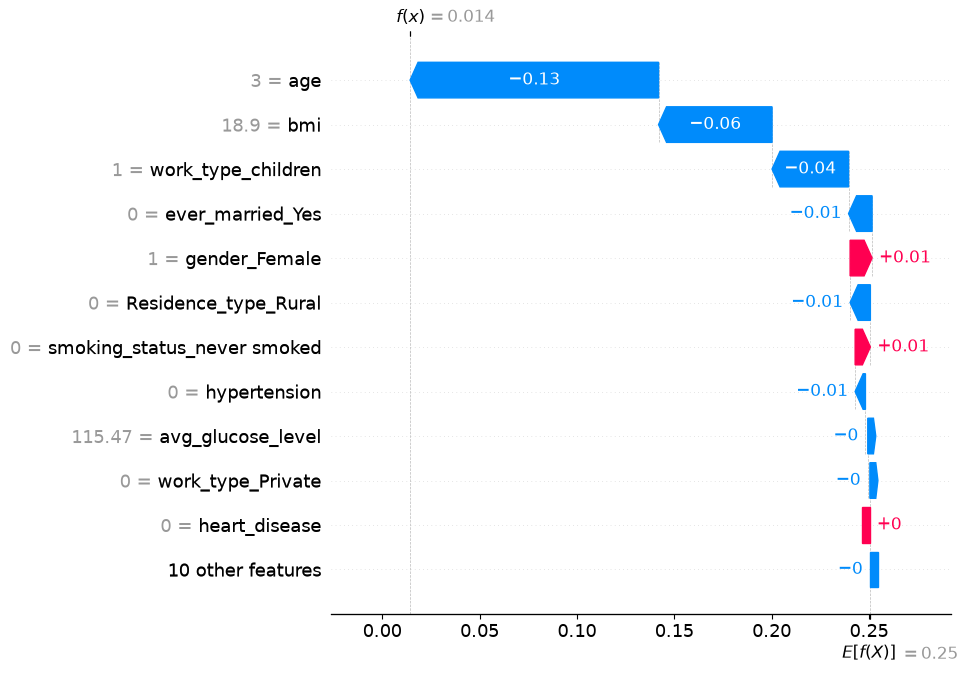

In [26]:

import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt

# Select the first observation from the Kernel SHAP sample
patient_index_svm = 0

patient_svm = X_explain.iloc[[patient_index_svm]]

# Actual class using the original test index
actual_svm = y_test.loc[patient_svm.index[0]]

# SVM prediction
predicted_svm = svm_model.predict(patient_svm)[0]
probability_svm = svm_model.predict_proba(
    patient_svm
)[0, 1]

# Extract SHAP values
svm_patient_shap = np.asarray(
    kernel_shap_values[patient_index_svm]
).reshape(-1)

svm_base_value = float(
    np.asarray(kernel_explainer.expected_value).reshape(-1)[0]
)

# Check reconstruction
reconstructed_svm = (
    svm_base_value + svm_patient_shap.sum()
)

print("SVM LOCAL EXPLANATION")
print("-" * 40)
print("Actual class:", actual_svm)
print("Predicted class:", predicted_svm)
print("Predicted stroke probability:",
      round(probability_svm, 6))
print("SHAP baseline:", round(svm_base_value, 6))
print("Reconstructed probability:",
      round(reconstructed_svm, 6))
print("Reconstruction error:",
      abs(reconstructed_svm - probability_svm))

# Generate local waterfall plot
explanation_svm = shap.Explanation(
    values=svm_patient_shap,
    base_values=svm_base_value,
    data=patient_svm.iloc[0].to_numpy(),
    feature_names=patient_svm.columns.tolist()
)

shap.plots.waterfall(
    explanation_svm,
    max_display=12,
    show=False
)

plt.savefig(
    "svm_kernel_shap_waterfall.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


**Local SVM interpretation:** This example is a correctly classified no-stroke observation. Read the executed output above for its model probability, SHAP baseline and additive reconstruction residual. These values are execution-dependent; the residual checks numerical additivity, not predictive accuracy.

### Task 6.2 — Global Kernel SHAP (50 sampled test records)

Use a larger reproducible sample for the final global view. Its ranking is exploratory because it covers 50 test records, compared with 1,022 for Tree SHAP. `nsamples=100` is a computational approximation setting, not 100 test records.

100%|██████████| 50/50 [01:01<00:00,  1.23s/it]


Kernel SHAP runtime: 61.41 seconds
SHAP shape: (50, 21)


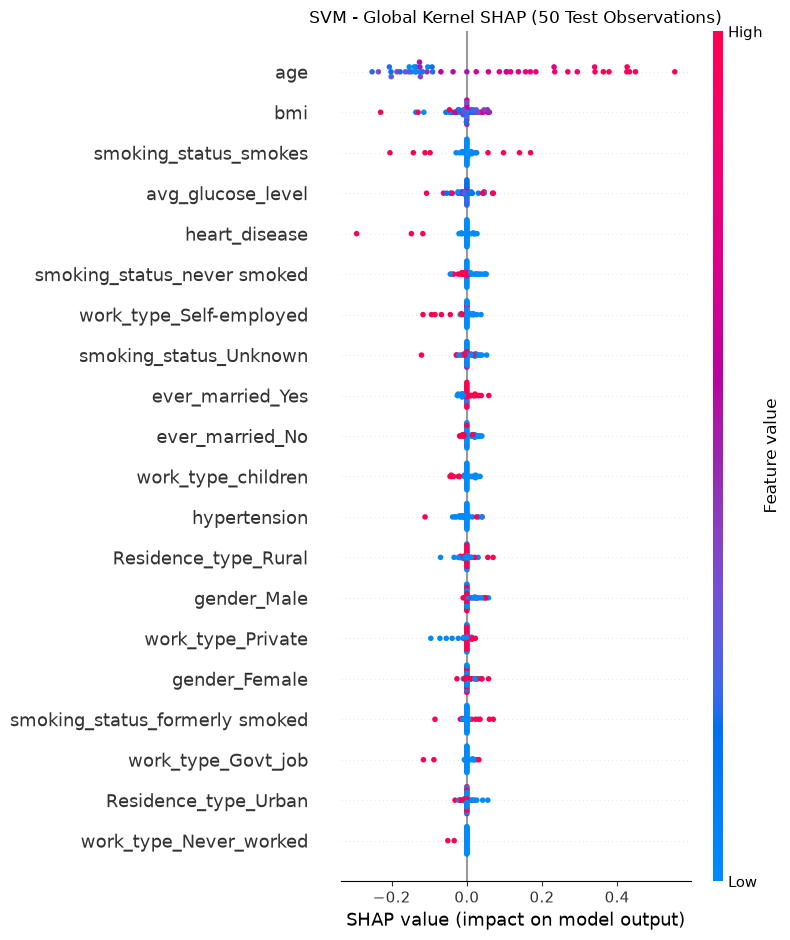


TOP 5 SVM FEATURES (50 OBSERVATIONS)
              Feature  Mean Absolute SHAP
                  age            0.192516
                  bmi            0.031249
smoking_status_smokes            0.024222
    avg_glucose_level            0.016955
        heart_disease            0.014830


In [27]:

import time
import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt

# Select 50 reproducible test observations
X_explain_50 = X_test.sample(
    n=50,
    random_state=42
)

# Reuse the existing Kernel SHAP explainer
start_time = time.perf_counter()

kernel_shap_values_50 = kernel_explainer.shap_values(
    X_explain_50,
    nsamples=100
)

kernel_runtime_50 = time.perf_counter() - start_time

print("Kernel SHAP runtime:",
      round(kernel_runtime_50, 2), "seconds")

print("SHAP shape:",
      np.asarray(kernel_shap_values_50).shape)

# Plot global explanation
shap.summary_plot(
    kernel_shap_values_50,
    X_explain_50,
    show=False
)

plt.title("SVM - Global Kernel SHAP (50 Test Observations)")
plt.tight_layout()

plt.savefig(
    "svm_kernel_shap_summary_50.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Calculate numerical global importance
svm_importance_50 = pd.DataFrame({
    "Feature": X_explain_50.columns,
    "Mean Absolute SHAP":
        np.abs(np.asarray(kernel_shap_values_50)).mean(axis=0)
})

svm_importance_50 = svm_importance_50.sort_values(
    "Mean Absolute SHAP",
    ascending=False
)

print("\nTOP 5 SVM FEATURES (50 OBSERVATIONS)")
print(svm_importance_50.head(5).to_string(index=False))

svm_importance_50.to_csv(
    "svm_kernel_shap_importance_50.csv",
    index=False
)


**Global SVM interpretation:** Read the executed runtime and top-five feature table directly above. Age was the leading feature in the saved experiment; the remaining rankings and numerical values should be copied from the final fresh run. The Random Forest global explanation covers 1,022 observations, whereas this SVM explanation covers 50 sampled observations. Do not directly compare raw SHAP magnitudes or assume explanation stability.

## Comparison and critical discussion

| Metric | Improved Random Forest | RBF SVM |
|---|---:|---:|
| Accuracy | 0.9384 | 0.7622 |
| Balanced accuracy | 0.5028 | 0.6948 |
| Stroke recall | 0.0200 | 0.6200 |
| Stroke precision | 0.0667 | 0.1216 |
| ROC AUC | 0.8149 | 0.7893 |
| Average precision | 0.1324 | 0.1556 |
| False negatives | 49 | 19 |
| False positives | 14 | 224 |
| Explanation | Tree SHAP, 1,022 records | Kernel SHAP, 50 records |

At the default decision threshold, SVM captures many more stroke-labelled records but at a large false-positive cost. The Random Forest has slightly higher ROC AUC but misses nearly all positives at this threshold. Neither model has been calibrated or externally validated for clinical deployment. SHAP explains model behaviour and does not establish medical causation. Changes in preprocessing and split mean the original lecturer baseline and improved RF cannot be compared as a controlled intervention.

## Reproducibility and submission checklist

- Confirm dataset source and lecturer repository URL/commit in the written report.
- Include `data/healthcare-dataset-stroke-data.csv`, `utils.py`, `00_data_exploration.py` and `03_shap.py` if keeping the reproduction cells.
- The improved preprocessing class is embedded in this notebook; no external `utils_improved.py` is needed for the main experiments.
- Restart kernel and **Run All** before submission; check outputs against the recorded results.
- Check SHAP package compatibility, any SVM warnings, plot file paths and execution time.
- Complete the lecturer's Word report and exactly three PowerPoint slides.

**Note:** This notebook was reorganised from saved working results. A fresh full execution has not been performed here because the dataset and original project scripts were not supplied alongside the notebook.